#Data Analytics Hackathon- SOLUTIONS

In [ ]:

import os

os.makedirs('/content/MyProject', exist_ok=True)

print("Folder created successfully!")


Folder created successfully!


In [ ]:
os.chdir('/content/MyProject')
print(os.getcwd())

/content/MyProject


In [ ]:
import os
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA_DIR = '/content'

con = duckdb.connect(database=':memory:')
con.execute("SET temp_directory='/tmp/duckdb_temp';")
con.execute("SET memory_limit='8GB';")

# 1. Load the 7 standard CSVs
standard_tables = [
    'stations',
    'riders',
    'fleet_partners',
    'batteries',
    'city_daily_context',
    'support_tickets',
    'station_hourly_status',
]

for t in standard_tables:
  path = os.path.join(DATA_DIR, f'{t}.csv')
  con.execute(f"""
        CREATE OR REPLACE VIEW {t} AS
        SELECT * FROM read_csv_auto(
            '{path}',
            strict_mode=false,
            null_padding=true,
            ignore_errors=true
        );
    """)

# 2. Load the 581 MB swap_events.csv bypassing auto-sniffer with strict_mode=false
swap_path = os.path.join(DATA_DIR, 'swap_events.csv')
con.execute(f"""
    CREATE OR REPLACE VIEW swap_events AS
    SELECT * FROM read_csv(
        '{swap_path}',
        delim=',',
        header=true,
        quote='"',
        escape='"',
        strict_mode=false,
        null_padding=true,
        ignore_errors=true,
        auto_detect=true,
        sample_size=20000
    );
""")

# Create aliases for Cells 2-8
con.execute('CREATE OR REPLACE VIEW raw_swaps AS SELECT * FROM swap_events;')
con.execute(
    'CREATE OR REPLACE VIEW station_hourly AS SELECT * FROM'
    ' station_hourly_status;'
)

print('=== ROW COUNTS ACROSS ALL 8 TABLES ===')
for tbl in standard_tables + ['swap_events']:
  cnt = con.execute(f'SELECT COUNT(*) FROM {tbl}').fetchone()[0]
  print(f'{tbl:<24}: {cnt:>12,} rows')

=== ROW COUNTS ACROSS ALL 8 TABLES ===
stations                :          152 rows
riders                  :       20,000 rows
fleet_partners          :           12 rows
batteries               :        6,500 rows
city_daily_context      :        3,282 rows
support_tickets         :       44,000 rows
station_hourly_status   :    1,487,712 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events             :    3,877,013 rows


In [ ]:
print('--- 1. CHECK DUPLICATES BY SYNC_MODE ---')
print(
    con.execute("""
    SELECT
        sync_mode,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT event_id) AS unique_event_ids,
        COUNT(*) - COUNT(DISTINCT event_id) AS exact_id_dups
    FROM raw_swaps
    GROUP BY 1
""").df()
)

print('\n--- 2. CHECK NEAR-DUPLICATES (SAME RIDER + STATION + TIMESTAMP) ---')
print(
    con.execute("""
    SELECT
        sync_mode,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (rider_id, station_id, event_ts, event_type)) AS unique_business_events
    FROM raw_swaps
    GROUP BY 1
""").df()
)

print('\n--- 3. CHECK FIRMWARE VERSIONS & HOUR-OF-DAY DISTRIBUTION ---')
fw_hours = con.execute("""
    SELECT
        station_firmware,
        EXTRACT(HOUR FROM CAST(event_ts AS TIMESTAMP)) AS hr,
        COUNT(*) AS swaps
    FROM raw_swaps
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()
print(fw_hours.pivot(index='hr', columns='station_firmware', values='swaps'))

print('\n--- 4. CHECK ODOMETER OUTLIERS (km_since_last_swap) ---')
print(
    con.execute("""
    SELECT
        COUNT(*) AS total_completed,
        COUNT(km_since_last_swap) AS non_null_km,
        SUM(CASE WHEN km_since_last_swap <= 0 THEN 1 ELSE 0 END) AS zero_or_neg,
        SUM(CASE WHEN km_since_last_swap > 250 THEN 1 ELSE 0 END) AS extreme_high_gt_250,
        PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY km_since_last_swap) AS median_km,
        PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY km_since_last_swap) AS p99_km
    FROM raw_swaps
    WHERE event_type = 'swap_completed'
""").df()
)

print('\n--- 5. CHECK EVENT_TYPE BREAKDOWN ---')
print(
    con.execute("""
    SELECT event_type, COUNT(*) AS cnt, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 2) AS pct
    FROM raw_swaps
    GROUP BY 1
    ORDER BY 2 DESC
""").df()
)

--- 1. CHECK DUPLICATES BY SYNC_MODE ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

       sync_mode  total_rows  unique_event_ids  exact_id_dups
0  offline_batch      591114            591114              0
1       realtime     3285899           3285899              0

--- 2. CHECK NEAR-DUPLICATES (SAME RIDER + STATION + TIMESTAMP) ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

       sync_mode  total_rows  unique_business_events
0  offline_batch      591114                  591113
1       realtime     3285899                 3285880

--- 3. CHECK FIRMWARE VERSIONS & HOUR-OF-DAY DISTRIBUTION ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

station_firmware  v3.2.0  v3.2.1
hr                              
0                   9714   13329
1                  10198   13284
2                  12257   13279
3                  15499   13323
4                  15838   15355
5                  13234   15276
6                  29073   32947
7                  33775   33114
8                  70893  100236
9                  92202  140731
10                 54702   82283
11                 41731   60969
12                141458  221248
13                150844  225466
14                 78054  100889
15                 53133   62423
16                 49145   63466
17                 49339   73081
18                 85273  135126
19                171025  276706
20                170384  275886
21                135101  219591
22                 68358  112586
23                  9944   15245

--- 4. CHECK ODOMETER OUTLIERS (km_since_last_swap) ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   total_completed  non_null_km  zero_or_neg  extreme_high_gt_250  median_km  \
0          3645809      3645809       7396.0               7316.0       60.0   

   p99_km  
0   106.8  

--- 5. CHECK EVENT_TYPE BREAKDOWN ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                  event_type      cnt    pct
0             swap_completed  3645809  94.04
1  failed_no_charged_battery   134389   3.47
2            abandoned_queue    68533   1.77
3         cancelled_by_rider    16712   0.43
4        failed_system_error    11570   0.30


##CORE QUESTIONS

core question 1

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,active_stations,total_attempts,completed_swaps,failure_rate_pct,abandon_rate_pct,revenue_millions_inr,rev_per_swap_inr,energy_cost_per_swap_inr,gross_margin_per_swap_inr,net_contrib_margin_per_swap_inr,avg_wait_min
0,2024-01-01,92,110348,105490.0,2.73,1.68,6.32,59.90,22.00,37.90,17.58,4.05
1,2024-02-01,92,111530,106581.0,2.71,1.72,6.39,59.93,21.90,38.03,17.92,4.07
2,2024-03-01,92,123900,118444.0,2.69,1.71,7.09,59.89,21.72,38.17,20.08,4.05
3,2024-04-01,92,131818,122836.0,4.38,2.43,7.37,60.00,21.59,38.41,20.96,4.07
4,2024-05-01,92,146278,128328.0,8.04,4.23,7.69,59.92,21.34,38.59,21.89,4.06
5,2024-06-01,92,148887,133742.0,6.66,3.52,8.00,59.84,21.04,38.80,22.78,4.06
6,2024-07-01,92,158688,151824.0,2.64,1.69,9.88,65.07,20.86,44.22,30.10,4.06
7,2024-08-01,102,172294,164930.0,2.57,1.71,10.72,65.02,20.65,44.38,29.79,4.06
8,2024-09-01,110,195884,187301.0,2.71,1.67,12.12,64.68,20.45,44.23,30.44,4.06
9,2024-10-01,122,229899,219836.0,2.67,1.70,14.58,66.31,20.22,46.09,32.99,4.07


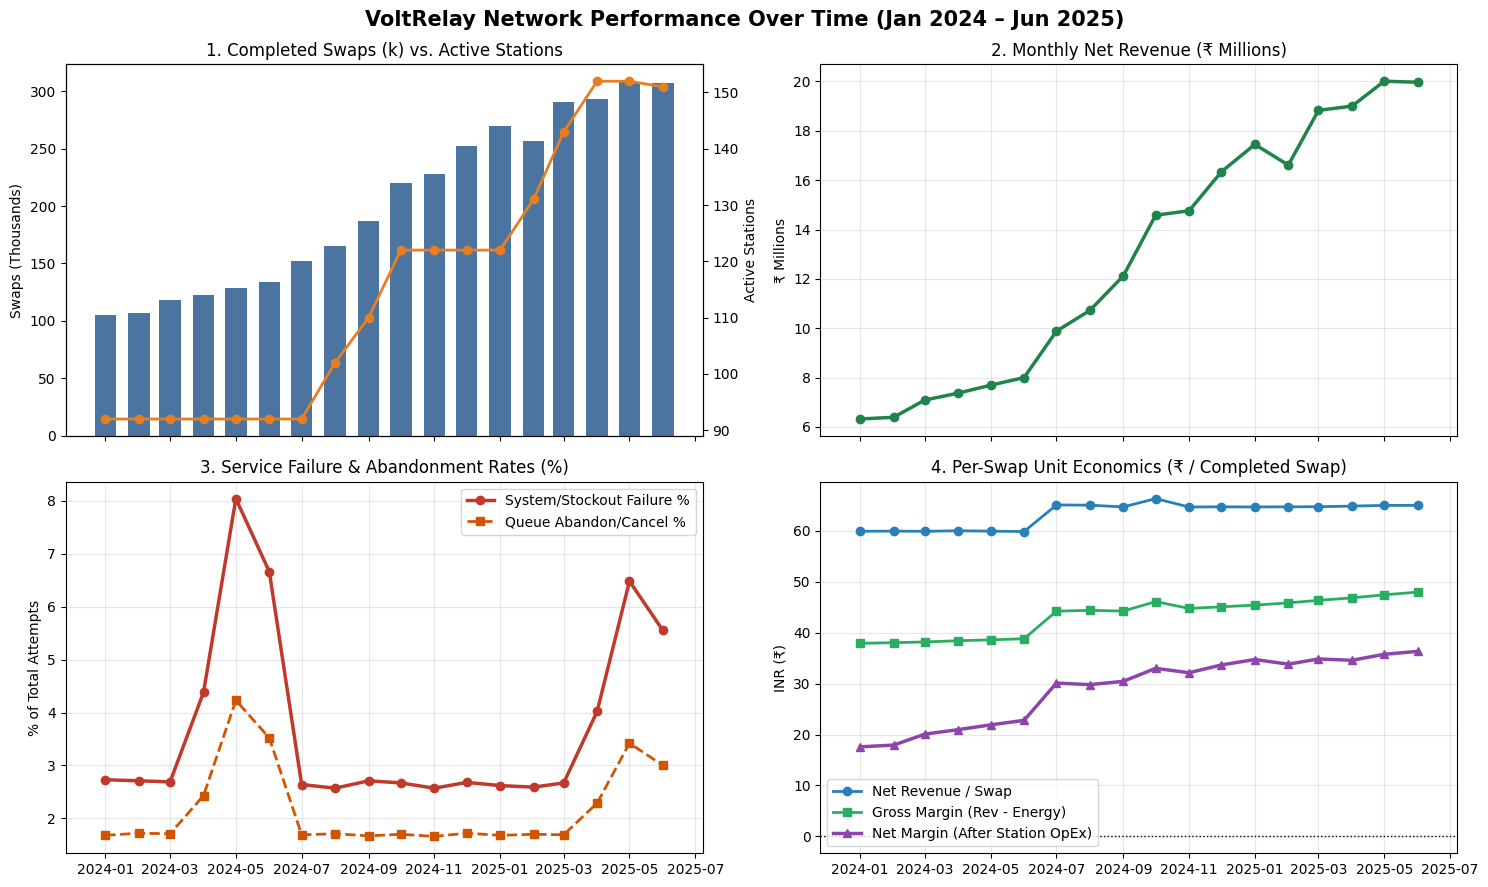

In [ ]:
con.execute("""
CREATE OR REPLACE VIEW clean_swaps AS
WITH deduped AS (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY rider_id, station_id, event_ts, event_type
               ORDER BY event_id
           ) AS rn
    FROM raw_swaps
)
SELECT
    d.* EXCLUDE (rn, event_ts, km_since_last_swap),
    -- UNCOMMENT BELOW IF CELL 2 SHOWS UTC OFFSET ON OLD FIRMWARE:
    -- CASE WHEN d.station_firmware = 'v3.1.0' THEN CAST(d.event_ts AS TIMESTAMP) + INTERVAL '330 minutes' ELSE CAST(d.event_ts AS TIMESTAMP) END AS event_ts,
    CAST(d.event_ts AS TIMESTAMP) AS event_ts,
    CASE WHEN d.km_since_last_swap BETWEEN 1 AND 250 THEN d.km_since_last_swap ELSE NULL END AS clean_km,
    s.city,
    s.zone,
    s.location_type,
    s.host_type,
    s.expansion_wave,
    s.charger_generation,
    s.grid_tariff_inr_kwh,
    s.monthly_rent_inr,
    s.monthly_maintenance_inr,
    r.partner_id,
    r.vehicle_class,
    r.plan_type,
    r.signup_date
FROM deduped d
LEFT JOIN stations s ON d.station_id = s.station_id
LEFT JOIN riders r ON d.rider_id = r.rider_id
WHERE d.rn = 1;
""")

q1_monthly = con.execute("""
WITH monthly_swaps AS (
    SELECT
        DATE_TRUNC('month', event_ts) AS month,
        COUNT(*) AS total_attempts,
        SUM(CASE WHEN event_type = 'swap_completed' THEN 1 ELSE 0 END) AS completed_swaps,
        SUM(CASE WHEN event_type LIKE 'failed_%' THEN 1 ELSE 0 END) AS failed_swaps,
        SUM(CASE WHEN event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) AS abandoned_swaps,
        SUM(CASE WHEN event_type = 'swap_completed' THEN amount_charged_inr ELSE 0 END) AS net_revenue_inr,
        SUM(CASE WHEN event_type = 'swap_completed' THEN COALESCE(energy_to_recharge_kwh, 0) * grid_tariff_inr_kwh ELSE 0 END) AS energy_cost_inr,
        AVG(CASE WHEN event_type = 'swap_completed' THEN queue_wait_sec / 60.0 END) AS avg_wait_min
    FROM clean_swaps
    GROUP BY 1
),
monthly_station_opex AS (
    SELECT
        m.month,
        SUM(s.monthly_rent_inr + s.monthly_maintenance_inr) AS total_station_opex_inr,
        COUNT(DISTINCT s.station_id) AS active_stations
    FROM (SELECT DISTINCT DATE_TRUNC('month', event_ts) AS month FROM clean_swaps) m
    CROSS JOIN stations s
    WHERE CAST(s.commissioned_date AS DATE) <= (CAST(m.month AS DATE) + INTERVAL '1 month' - INTERVAL '1 day')
      AND (s.decommissioned_date IS NULL OR CAST(s.decommissioned_date AS DATE) >= CAST(m.month AS DATE))
    GROUP BY 1
)
SELECT
    ms.month,
    so.active_stations,
    ms.total_attempts,
    ms.completed_swaps,
    ROUND(100.0 * ms.failed_swaps / ms.total_attempts, 2) AS failure_rate_pct,
    ROUND(100.0 * ms.abandoned_swaps / ms.total_attempts, 2) AS abandon_rate_pct,
    ROUND(ms.net_revenue_inr / 1e6, 2) AS revenue_millions_inr,
    ROUND(ms.net_revenue_inr / NULLIF(ms.completed_swaps, 0), 2) AS rev_per_swap_inr,
    ROUND(ms.energy_cost_inr / NULLIF(ms.completed_swaps, 0), 2) AS energy_cost_per_swap_inr,
    ROUND((ms.net_revenue_inr - ms.energy_cost_inr) / NULLIF(ms.completed_swaps, 0), 2) AS gross_margin_per_swap_inr,
    ROUND((ms.net_revenue_inr - ms.energy_cost_inr - so.total_station_opex_inr) / NULLIF(ms.completed_swaps, 0), 2) AS net_contrib_margin_per_swap_inr,
    ROUND(ms.avg_wait_min, 2) AS avg_wait_min
FROM monthly_swaps ms
LEFT JOIN monthly_station_opex so ON ms.month = so.month
ORDER BY 1;
""").df()

display(q1_monthly)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
fig.suptitle(
    'VoltRelay Network Performance Over Time (Jan 2024 – Jun 2025)',
    fontsize=15,
    fontweight='bold',
)

ax1 = axes[0, 0]
ax1.bar(
    q1_monthly['month'],
    q1_monthly['completed_swaps'] / 1000,
    width=20,
    color='#2b5c8f',
    alpha=0.85,
)
ax1_t = ax1.twinx()
ax1_t.plot(
    q1_monthly['month'],
    q1_monthly['active_stations'],
    color='#e67e22',
    marker='o',
    lw=2,
)
ax1.set_title('1. Completed Swaps (k) vs. Active Stations')
ax1.set_ylabel('Swaps (Thousands)')
ax1_t.set_ylabel('Active Stations')

axes[0, 1].plot(
    q1_monthly['month'],
    q1_monthly['revenue_millions_inr'],
    color='#1e8449',
    marker='o',
    lw=2.5,
)
axes[0, 1].set_title('2. Monthly Net Revenue (₹ Millions)')
axes[0, 1].set_ylabel('₹ Millions')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(
    q1_monthly['month'],
    q1_monthly['failure_rate_pct'],
    color='#c0392b',
    marker='o',
    lw=2.5,
    label='System/Stockout Failure %',
)
axes[1, 0].plot(
    q1_monthly['month'],
    q1_monthly['abandon_rate_pct'],
    color='#d35400',
    marker='s',
    lw=2,
    linestyle='--',
    label='Queue Abandon/Cancel %',
)
axes[1, 0].set_title('3. Service Failure & Abandonment Rates (%)')
axes[1, 0].set_ylabel('% of Total Attempts')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(
    q1_monthly['month'],
    q1_monthly['rev_per_swap_inr'],
    color='#2980b9',
    marker='o',
    lw=2,
    label='Net Revenue / Swap',
)
axes[1, 1].plot(
    q1_monthly['month'],
    q1_monthly['gross_margin_per_swap_inr'],
    color='#27ae60',
    marker='s',
    lw=2,
    label='Gross Margin (Rev - Energy)',
)
axes[1, 1].plot(
    q1_monthly['month'],
    q1_monthly['net_contrib_margin_per_swap_inr'],
    color='#8e44ad',
    marker='^',
    lw=2.5,
    label='Net Margin (After Station OpEx)',
)
axes[1, 1].axhline(0, color='black', linestyle=':', lw=1)
axes[1, 1].set_title('4. Per-Swap Unit Economics (₹ / Completed Swap)')
axes[1, 1].set_ylabel('INR (₹)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

core que 2

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 2A. VEHICLE CLASS (2W vs 3W) SUMMARY ---


,total_attempts,stockout_fail_pct,sys_error_pct,abandon_pct,avg_wait_min,p90_wait_min
vehicle_class,,,,,,
2W,143874.041667,2.875000,0.298750,1.939583,4.054167,7.260833
3W,17667.291667,6.304167,0.294583,3.647500,4.053750,7.480000


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- 2B. WEATHER & EXTREME EVENT IMPACT ---


,weather_regime,total_attempts,fail_rate_pct,sys_error_pct,abandon_pct,avg_wait_min
0,Heat Alert,190246,9.89,0.30,5.04,4.05
1,Heavy Rain (>15mm),384952,3.55,0.30,2.13,4.05
2,Normal Weather,3298721,3.44,0.30,2.04,4.05
3,Flood Disruption,3073,2.77,0.33,1.69,4.05


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- 2C. TOP 20 STATIONS DRIVING NETWORK FAILURES/ABANDONMENTS ---


,station_id,city,charger_generation,host_type,attempts,bad_outcomes,bad_outcome_pct,cum_share_of_all_failures_pct
0,STN-DEL-043,Delhi NCR,Gen1,mall_parking,49597,4271.0,8.61,1.85
1,STN-JAI-138,Jaipur,Gen1,kirana,48945,4242.0,8.67,3.68
2,STN-HYD-072,Hyderabad,Gen1,kirana,51765,4176.0,8.07,5.49
3,STN-DEL-050,Delhi NCR,Gen1,fuel_retailer,47060,4053.0,8.61,7.24
4,STN-JAI-141,Jaipur,Gen1,mall_parking,45592,3981.0,8.73,8.96
5,STN-JAI-137,Jaipur,Gen1,owned_lot,44370,3881.0,8.75,10.64
6,STN-HYD-070,Hyderabad,Gen1,kirana,49688,3768.0,7.58,12.27
7,STN-JAI-140,Jaipur,Gen1,mall_parking,44115,3733.0,8.46,13.89
8,STN-JAI-134,Jaipur,Gen1,kirana,42925,3612.0,8.41,15.45
9,STN-DEL-047,Delhi NCR,Gen1,owned_lot,41593,3509.0,8.44,16.97


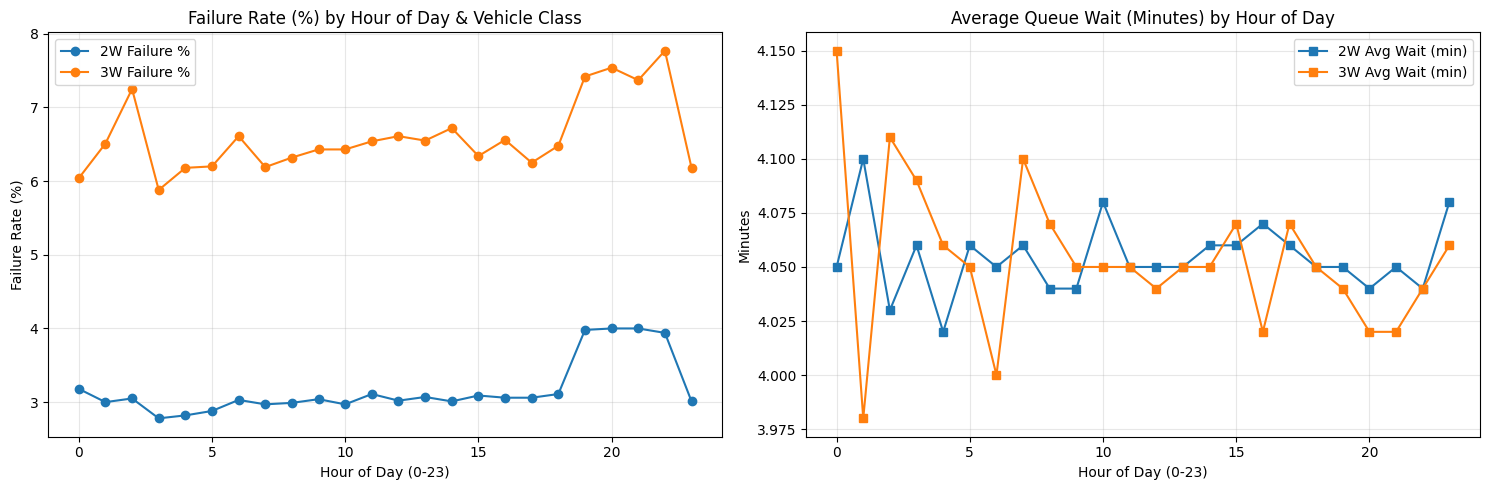

In [ ]:
q2_hourly = con.execute("""
SELECT
    vehicle_class,
    EXTRACT(HOUR FROM event_ts) AS hour_of_day,
    COUNT(*) AS total_attempts,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_no_charged_battery' THEN 1 ELSE 0 END) / COUNT(*), 2) AS stockout_fail_pct,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_system_error' THEN 1 ELSE 0 END) / COUNT(*), 2) AS sys_error_pct,
    ROUND(100.0 * SUM(CASE WHEN event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) / COUNT(*), 2) AS abandon_pct,
    ROUND(AVG(queue_wait_sec) / 60.0, 2) AS avg_wait_min,
    ROUND(PERCENTILE_CONT(0.90) WITHIN GROUP (ORDER BY queue_wait_sec) / 60.0, 2) AS p90_wait_min
FROM clean_swaps
GROUP BY 1, 2
ORDER BY 1, 2;
""").df()

print('--- 2A. VEHICLE CLASS (2W vs 3W) SUMMARY ---')
display(
    q2_hourly.groupby('vehicle_class')[
        [
            'total_attempts',
            'stockout_fail_pct',
            'sys_error_pct',
            'abandon_pct',
            'avg_wait_min',
            'p90_wait_min',
        ]
    ].mean()
)

q2_weather = con.execute("""
SELECT
    CASE
        WHEN c.flood_disruption THEN 'Flood Disruption'
        WHEN c.heat_alert THEN 'Heat Alert'
        WHEN c.rainfall_mm > 15 THEN 'Heavy Rain (>15mm)'
        ELSE 'Normal Weather'
    END AS weather_regime,
    COUNT(*) AS total_attempts,
    ROUND(100.0 * SUM(CASE WHEN s.event_type LIKE 'failed_%' THEN 1 ELSE 0 END) / COUNT(*), 2) AS fail_rate_pct,
    ROUND(100.0 * SUM(CASE WHEN s.event_type = 'failed_system_error' THEN 1 ELSE 0 END) / COUNT(*), 2) AS sys_error_pct,
    ROUND(100.0 * SUM(CASE WHEN s.event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) / COUNT(*), 2) AS abandon_pct,
    ROUND(AVG(s.queue_wait_sec) / 60.0, 2) AS avg_wait_min
FROM clean_swaps s
LEFT JOIN city_daily_context c
    ON s.city = c.city AND CAST(s.event_ts AS DATE) = CAST(c.date AS DATE)
GROUP BY 1
ORDER BY fail_rate_pct DESC;
""").df()

print('\n--- 2B. WEATHER & EXTREME EVENT IMPACT ---')
display(q2_weather)

q2_pareto = con.execute("""
WITH stn_fails AS (
    SELECT
        station_id, city, charger_generation, host_type,
        COUNT(*) AS attempts,
        SUM(CASE WHEN event_type LIKE 'failed_%' OR event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) AS bad_outcomes
    FROM clean_swaps
    GROUP BY 1, 2, 3, 4
)
SELECT
    station_id, city, charger_generation, host_type, attempts, bad_outcomes,
    ROUND(100.0 * bad_outcomes / attempts, 2) AS bad_outcome_pct,
    ROUND(100.0 * SUM(bad_outcomes) OVER (ORDER BY bad_outcomes DESC) / SUM(bad_outcomes) OVER (), 2) AS cum_share_of_all_failures_pct
FROM stn_fails
ORDER BY bad_outcomes DESC
LIMIT 20;
""").df()

print('\n--- 2C. TOP 20 STATIONS DRIVING NETWORK FAILURES/ABANDONMENTS ---')
display(q2_pareto)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for vc, grp in q2_hourly.groupby('vehicle_class'):
  axes[0].plot(
      grp['hour_of_day'],
      grp['stockout_fail_pct'] + grp['sys_error_pct'],
      marker='o',
      label=f'{vc} Failure %',
  )
  axes[1].plot(
      grp['hour_of_day'],
      grp['avg_wait_min'],
      marker='s',
      label=f'{vc} Avg Wait (min)',
  )
axes[0].set_title('Failure Rate (%) by Hour of Day & Vehicle Class')
axes[0].set_xlabel('Hour of Day (0-23)')
axes[0].set_ylabel('Failure Rate (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Average Queue Wait (Minutes) by Hour of Day')
axes[1].set_xlabel('Hour of Day (0-23)')
axes[1].set_ylabel('Minutes')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

core que 3

In [ ]:
q3_station_perf = con.execute("""
WITH swap_agg AS (
    SELECT
        station_id,
        COUNT(*) AS total_attempts,
        SUM(CASE WHEN event_type = 'swap_completed' THEN 1 ELSE 0 END) AS completed_swaps,
        ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_no_charged_battery' THEN 1 ELSE 0 END) / COUNT(*), 2) AS stockout_fail_pct,
        ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_system_error' THEN 1 ELSE 0 END) / COUNT(*), 2) AS sys_err_pct,
        ROUND(AVG(queue_wait_sec)/60.0, 2) AS avg_wait_min
    FROM clean_swaps
    GROUP BY 1
),
telemetry_agg AS (
    SELECT
        station_id,
        ROUND(AVG(avg_charge_minutes), 1) AS avg_charge_min,
        ROUND(AVG(cabinet_temp_c), 1) AS avg_cab_temp_c,
        ROUND(SUM(outage_minutes) / 60.0, 1) AS total_outage_hrs,
        ROUND(AVG(packs_quarantined), 2) AS avg_quarantined_packs,
        ROUND(100.0 * SUM(CASE WHEN charged_2w_min = 0 THEN 1 ELSE 0 END) / NULLIF(COUNT(charged_2w_min), 0), 2) AS pct_hours_2w_stockout
    FROM station_hourly
    WHERE telemetry_status != 'missing'
    GROUP BY 1
),
ticket_agg AS (
    SELECT station_id, COUNT(*) AS total_tickets
    FROM support_tickets
    WHERE resolution_status != 'duplicate'
    GROUP BY 1
)
SELECT
    s.city,
    s.charger_generation,
    s.host_type,
    s.expansion_wave,
    COUNT(DISTINCT s.station_id) AS num_stations,
    ROUND(AVG(sa.completed_swaps), 0) AS avg_completed_per_stn,
    ROUND(AVG(sa.stockout_fail_pct), 2) AS avg_stockout_fail_pct,
    ROUND(AVG(sa.sys_err_pct), 2) AS avg_sys_err_pct,
    ROUND(AVG(sa.avg_wait_min), 2) AS avg_wait_min,
    ROUND(AVG(ta.avg_charge_min), 1) AS avg_charge_turnaround_min,
    ROUND(AVG(ta.total_outage_hrs), 1) AS avg_outage_hrs_per_stn,
    ROUND(AVG(ta.pct_hours_2w_stockout), 2) AS avg_pct_hrs_stockout,
    ROUND(1000.0 * SUM(COALESCE(tk.total_tickets, 0)) / NULLIF(SUM(sa.completed_swaps), 0), 2) AS tickets_per_1k_swaps
FROM stations s
LEFT JOIN swap_agg sa ON s.station_id = sa.station_id
LEFT JOIN telemetry_agg ta ON s.station_id = ta.station_id
LEFT JOIN ticket_agg tk ON s.station_id = tk.station_id
GROUP BY 1, 2, 3, 4
ORDER BY avg_stockout_fail_pct DESC;
""").df()

print('--- 3A. STATION PERFORMANCE BY CITY, CHARGER GEN, HOST & WAVE ---')
display(q3_station_perf.head(25))

print('\n--- 3B. ROLLUP BY CHARGER GENERATION ---')
display(
    q3_station_perf.groupby('charger_generation')[
        [
            'num_stations',
            'avg_stockout_fail_pct',
            'avg_sys_err_pct',
            'avg_wait_min',
            'avg_charge_turnaround_min',
            'tickets_per_1k_swaps',
        ]
    ].mean()
)

print('\n--- 3C. ROLLUP BY HOST TYPE ---')
display(
    q3_station_perf.groupby('host_type')[
        [
            'num_stations',
            'avg_stockout_fail_pct',
            'avg_sys_err_pct',
            'avg_outage_hrs_per_stn',
            'tickets_per_1k_swaps',
        ]
    ].mean()
)

print('\n--- 3D. ROLLUP BY EXPANSION WAVE ---')
display(
    q3_station_perf.groupby('expansion_wave')[
        [
            'num_stations',
            'avg_completed_per_stn',
            'avg_stockout_fail_pct',
            'avg_wait_min',
            'tickets_per_1k_swaps',
        ]
    ].mean()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 3A. STATION PERFORMANCE BY CITY, CHARGER GEN, HOST & WAVE ---


,city,charger_generation,host_type,expansion_wave,num_stations,avg_completed_per_stn,avg_stockout_fail_pct,avg_sys_err_pct,avg_wait_min,avg_charge_turnaround_min,avg_outage_hrs_per_stn,avg_pct_hrs_stockout,tickets_per_1k_swaps
0,Jaipur,Gen1,owned_lot,Launch,1,40489.0,5.36,0.27,4.05,94.8,4.0,7.08,14.00
1,Delhi NCR,Gen1,owned_lot,Launch,5,31613.0,5.33,0.30,4.05,94.0,2.6,2.83,14.78
2,Jaipur,Gen1,mall_parking,Launch,5,32590.0,5.29,0.28,4.05,94.7,2.0,3.89,14.51
3,Delhi NCR,Gen1,fuel_retailer,Launch,4,31117.0,5.20,0.29,4.04,94.0,1.8,3.91,14.28
4,Jaipur,Gen1,kirana,Launch,4,35115.0,5.18,0.28,4.05,94.8,2.3,3.49,14.18
5,Delhi NCR,Gen1,kirana,Launch,1,27105.0,5.15,0.33,4.05,94.1,3.0,2.58,14.61
6,Delhi NCR,Gen1,mall_parking,Launch,3,35941.0,5.05,0.30,4.05,94.0,4.3,4.07,13.92
7,Hyderabad,Gen1,kirana,Launch,4,40768.0,4.71,0.30,4.05,91.2,0.3,1.99,13.22
8,Hyderabad,Gen1,fuel_retailer,Launch,4,32054.0,4.42,0.30,4.05,91.2,1.3,1.82,12.61
9,Hyderabad,Gen1,owned_lot,Launch,3,30671.0,4.42,0.29,4.04,91.2,1.0,1.06,12.70



--- 3B. ROLLUP BY CHARGER GENERATION ---


,num_stations,avg_stockout_fail_pct,avg_sys_err_pct,avg_wait_min,avg_charge_turnaround_min,tickets_per_1k_swaps
charger_generation,,,,,,
Gen1,2.833333,4.072778,0.297222,4.052222,91.372222,11.836111
Gen2,2.206897,2.746552,0.308276,4.049655,64.289655,10.555172
Gen3,1.480000,2.664400,0.309200,4.053600,42.148000,12.065600



--- 3C. ROLLUP BY HOST TYPE ---


,num_stations,avg_stockout_fail_pct,avg_sys_err_pct,avg_outage_hrs_per_stn,tickets_per_1k_swaps
host_type,,,,,
fuel_retailer,1.722222,2.878333,0.298333,1.677778,11.113333
kirana,2.235294,3.163529,0.316471,1.988235,11.745294
mall_parking,2.200000,2.998500,0.308000,1.860000,11.344000
owned_lot,2.294118,3.177059,0.300588,1.664706,11.423529



--- 3D. ROLLUP BY EXPANSION WAVE ---


,num_stations,avg_completed_per_stn,avg_stockout_fail_pct,avg_wait_min,tickets_per_1k_swaps
expansion_wave,,,,,
Launch,2.875000,32162.281250,3.465000,4.050937,10.750937
Wave1_2024H2,1.363636,15864.772727,2.710000,4.050000,11.460000
Wave2_2025H1,1.666667,7440.500000,2.726111,4.055000,12.480000


core que 4

In [ ]:
q4_batteries = con.execute("""
WITH battery_usage AS (
    SELECT
        battery_in_id AS battery_id,
        COUNT(*) AS total_swaps_returned,
        AVG(clean_km) AS avg_delivered_km,
        PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY clean_km) AS median_delivered_km,
        AVG(soh_in_pct) AS avg_observed_soh_pct,
        AVG(soc_in_pct) AS avg_return_soc_pct,
        AVG(energy_to_recharge_kwh) AS avg_recharge_kwh
    FROM clean_swaps
    WHERE event_type = 'swap_completed' AND battery_in_id IS NOT NULL
    GROUP BY 1
)
SELECT
    b.pack_type,
    b.supplier,
    b.manufacturing_lot,
    b.bms_firmware,
    COUNT(DISTINCT b.battery_id) AS pack_count,
    ROUND(AVG(b.purchase_cost_inr), 0) AS avg_cost_inr,
    ROUND(AVG(b.initial_soh_pct - b.current_soh_pct), 2) AS avg_soh_drop_pct,
    ROUND(AVG(b.current_soh_pct), 2) AS avg_current_soh_pct,
    ROUND(100.0 * SUM(CASE WHEN b.retired_date IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 2) AS retired_pct,
    ROUND(AVG(u.total_swaps_returned), 1) AS avg_cycles_observed,
    ROUND(AVG(u.avg_delivered_km), 1) AS avg_delivered_km_per_swap,
    ROUND(AVG(u.avg_recharge_kwh), 2) AS avg_recharge_kwh
FROM batteries b
LEFT JOIN battery_usage u ON b.battery_id = u.battery_id
GROUP BY 1, 2, 3, 4
ORDER BY avg_soh_drop_pct DESC;
""").df()

print('--- 4A. WORST PERFORMING BATTERY COHORTS (BY SOH DROP & RANGE) ---')
display(q4_batteries.head(20))

print('\n--- 4B. SUPPLIER-LEVEL COMPARISON ---')
display(
    q4_batteries.groupby(['pack_type', 'supplier'])[
        [
            'pack_count',
            'avg_cost_inr',
            'avg_soh_drop_pct',
            'avg_current_soh_pct',
            'retired_pct',
            'avg_delivered_km_per_swap',
        ]
    ].mean()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 4A. WORST PERFORMING BATTERY COHORTS (BY SOH DROP & RANGE) ---


,pack_type,supplier,manufacturing_lot,bms_firmware,pack_count,avg_cost_inr,avg_soh_drop_pct,avg_current_soh_pct,retired_pct,avg_cycles_observed,avg_delivered_km_per_swap,avg_recharge_kwh
0,2W_2.1kWh,Kyron,KY-2407,BMS-4.1,163,31917.0,38.78,60.37,100.00,516.9,48.7,1.75
1,2W_2.1kWh,Kyron,KY-2408,BMS-4.1,179,31896.0,38.76,60.49,100.00,515.6,48.7,1.75
2,2W_2.1kWh,Kyron,KY-2407,BMS-4.0,138,32072.0,38.75,60.41,100.00,515.5,48.7,1.75
3,2W_2.1kWh,Kyron,KY-2409,BMS-4.1,160,32012.0,38.75,60.42,100.00,515.0,48.7,1.75
4,2W_2.1kWh,Kyron,KY-2408,BMS-4.0,145,32049.0,38.68,60.49,100.00,515.4,48.6,1.75
5,2W_2.1kWh,Kyron,KY-2409,BMS-4.2,149,31935.0,38.62,60.60,100.00,513.8,48.7,1.75
6,2W_2.1kWh,Kyron,KY-2408,BMS-4.2,147,32046.0,38.60,60.62,100.00,514.3,48.7,1.75
7,2W_2.1kWh,Kyron,KY-2409,BMS-4.0,153,31944.0,38.56,60.67,100.00,513.7,48.7,1.75
8,2W_2.1kWh,Kyron,KY-2407,BMS-4.2,151,31996.0,38.46,60.74,100.00,511.1,48.7,1.75
9,3W_4.8kWh,Kyron,KY-2407,BMS-4.2,7,69012.0,30.54,68.39,100.00,391.0,81.4,4.37



--- 4B. SUPPLIER-LEVEL COMPARISON ---


pack_count  avg_cost_inr  avg_soh_drop_pct  \
pack_type supplier                                               
2W_2.1kWh Amptek     22.875000  32008.458333         19.245208   
          Cellora    37.469136  31983.160494         19.211852   
          Kyron     153.888889  31985.222222         38.662222   
3W_4.8kWh Amptek      4.354167  67804.250000         12.702917   
          Cellora     6.419753  67986.950617         12.687901   
          Kyron       7.027778  67935.638889         17.027500   

                    avg_current_soh_pct  retired_pct  \
pack_type supplier                                     
2W_2.1kWh Amptek              79.945417     0.000000   
          Cellora             79.969753     0.000000   
          Kyron               60.534444   100.000000   
3W_4.8kWh Amptek              86.527292     0.000000   
          Cellora             86.506790     0.000000   
          Kyron               82.221111    16.715278   

                    avg_delivered_km_per_swap  
pack_type supplier                             
2W_2.1kWh Amptek                    60.920833  
          Cellora                   60.913580  
          Kyron                     48.688889  
3W_4.8kWh Amptek                    90.368750  
          Cellora                   90.316049  
          Kyron                     88.250000

core que 5

In [ ]:
q5_tariffs = con.execute("""
SELECT
    city,
    tariff_code,
    COUNT(*) AS attempts,
    SUM(CASE WHEN event_type = 'swap_completed' THEN 1 ELSE 0 END) AS completed_swaps,
    ROUND(100.0 * SUM(CASE WHEN event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) / COUNT(*), 2) AS abandon_pct,
    ROUND(AVG(CASE WHEN event_type = 'swap_completed' THEN list_price_inr END), 2) AS avg_list_price,
    ROUND(AVG(CASE WHEN event_type = 'swap_completed' THEN discount_inr END), 2) AS avg_discount,
    ROUND(AVG(CASE WHEN event_type = 'swap_completed' THEN amount_charged_inr END), 2) AS avg_net_rev,
    ROUND(AVG(CASE WHEN event_type = 'swap_completed' THEN amount_charged_inr - (COALESCE(energy_to_recharge_kwh,0) * grid_tariff_inr_kwh) END), 2) AS gross_margin_per_swap
FROM clean_swaps
GROUP BY 1, 2
ORDER BY city, completed_swaps DESC;
""").df()

print('--- 5A. TARIFF & PILOT PRICING PERFORMANCE BY CITY ---')
display(q5_tariffs)

q5_partners = con.execute("""
SELECT
    COALESCE(fp.partner_name, 'Retail / Non-Fleet') AS partner_name,
    COALESCE(fp.partner_segment, 'retail') AS segment,
    s.vehicle_class,
    fp.discount_pct AS initial_discount_pct,
    fp.discount_pct_after_amendment AS amended_discount_pct,
    fp.peak_surcharge_billable,
    COUNT(*) AS completed_swaps,
    ROUND(SUM(s.amount_charged_inr) / 1e6, 2) AS total_rev_millions_inr,
    ROUND(AVG(s.amount_charged_inr), 2) AS avg_net_rev_per_swap,
    ROUND(AVG(COALESCE(s.energy_to_recharge_kwh,0) * s.grid_tariff_inr_kwh), 2) AS avg_energy_cost_per_swap,
    ROUND(AVG(s.amount_charged_inr - (COALESCE(s.energy_to_recharge_kwh,0) * s.grid_tariff_inr_kwh)), 2) AS gross_margin_per_swap,
    ROUND(SUM(s.amount_charged_inr - (COALESCE(s.energy_to_recharge_kwh,0) * s.grid_tariff_inr_kwh)) / 1e6, 2) AS total_gross_margin_millions_inr
FROM clean_swaps s
LEFT JOIN fleet_partners fp ON s.partner_id = fp.partner_id
WHERE s.event_type = 'swap_completed'
GROUP BY 1, 2, 3, 4, 5, 6
ORDER BY total_rev_millions_inr DESC;
""").df()

print('\n--- 5B. FLEET PARTNER VS RETAIL UNIT ECONOMICS ---')
display(q5_partners)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 5A. TARIFF & PILOT PRICING PERFORMANCE BY CITY ---


,city,tariff_code,attempts,completed_swaps,abandon_pct,avg_list_price,avg_discount,avg_net_rev,gross_margin_per_swap
0,Bengaluru,PARTNER,555899,529830.0,1.80,69.68,8.75,63.26,43.19
1,Bengaluru,STD,142455,136355.0,1.67,65.41,0.00,65.41,46.83
2,Bengaluru,PEAK,104672,100177.0,1.69,67.37,0.00,82.37,64.96
3,Bengaluru,OFFPEAK,22296,21330.0,1.63,67.40,0.00,59.41,41.98
4,Delhi NCR,PARTNER,507814,469970.0,2.70,69.34,8.81,60.53,41.05
5,Delhi NCR,STD,261093,242409.0,2.54,66.48,0.00,66.48,48.73
6,Hyderabad,PARTNER,463337,431699.0,2.46,69.49,8.91,60.59,40.82
7,Hyderabad,STD,248591,232611.0,2.34,66.06,0.00,66.06,48.31
8,Jaipur,PARTNER,314730,289654.0,2.84,69.67,8.74,60.93,40.83
9,Jaipur,STD,172901,159709.0,2.70,66.24,0.00,66.24,48.21


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- 5B. FLEET PARTNER VS RETAIL UNIT ECONOMICS ---


,partner_name,segment,vehicle_class,initial_discount_pct,amended_discount_pct,peak_surcharge_billable,completed_swaps,total_rev_millions_inr,avg_net_rev_per_swap,avg_energy_cost_per_swap,gross_margin_per_swap,total_gross_margin_millions_inr
0,Retail / Non-Fleet,retail,2W,NaN,NaN,None,1168361,76.95,65.86,16.89,48.97,57.22
1,FeastFly,food_delivery,2W,10.0,NaN,Y,497760,29.83,59.93,16.89,43.05,21.43
2,ZipDrop,quick_commerce,2W,12.0,28.0,N,523625,26.17,49.98,17.65,32.33,16.93
3,ParcelNest,ecom_logistics,2W,15.0,NaN,Y,286575,15.65,54.61,16.89,37.72,10.81
4,CargoTuk,cargo_3w,3W,8.0,NaN,Y,134084,13.33,99.44,40.76,58.68,7.87
5,Swiggle Go,food_delivery,2W,11.0,NaN,N,226961,12.93,56.95,16.89,40.06,9.09
6,QuickCart,quick_commerce,2W,9.0,NaN,Y,124567,7.53,60.42,16.87,43.55,5.42
7,Retail / Non-Fleet,retail,3W,NaN,NaN,None,67604,7.43,109.84,40.45,69.40,4.69
8,RideMitra,bike_taxi,2W,6.0,NaN,Y,115563,7.04,60.92,16.92,44.00,5.09
9,HaulKing,cargo_3w,3W,7.0,NaN,Y,54274,5.45,100.34,40.73,59.61,3.24


core que 6

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

q6_riders = con.execute("""
WITH new_riders AS (
    SELECT *
    FROM riders
    WHERE CAST(signup_date AS DATE) BETWEEN DATE '2024-01-01' AND DATE '2025-04-30'
),
first_week_exp AS (
    SELECT
        r.rider_id,
        COUNT(s.event_id) AS wk1_attempts,
        SUM(CASE WHEN s.event_type = 'swap_completed' THEN 1 ELSE 0 END) AS wk1_completed,
        SUM(CASE WHEN s.event_type LIKE 'failed_%' THEN 1 ELSE 0 END) AS wk1_failures,
        SUM(CASE WHEN s.event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) AS wk1_abandons,
        AVG(s.queue_wait_sec) / 60.0 AS wk1_avg_wait_min,
        MAX(s.queue_wait_sec) / 60.0 AS wk1_max_wait_min,
        AVG(s.soh_out_pct) AS wk1_avg_battery_soh,
        AVG(s.amount_charged_inr) AS wk1_avg_price_paid,
        MAX(CASE WHEN s.tariff_code = 'PEAK' THEN 1 ELSE 0 END) AS wk1_hit_peak_price
    FROM new_riders r
    LEFT JOIN clean_swaps s
        ON r.rider_id = s.rider_id
        AND CAST(s.event_ts AS DATE) BETWEEN CAST(r.signup_date AS DATE) AND CAST(r.signup_date AS DATE) + INTERVAL '7 days'
    GROUP BY 1
),
retention_outcome AS (
    SELECT
        r.rider_id,
        MAX(CASE WHEN CAST(s.event_ts AS DATE) BETWEEN CAST(r.signup_date AS DATE) + INTERVAL '31 days' AND CAST(r.signup_date AS DATE) + INTERVAL '60 days'
                 AND s.event_type = 'swap_completed' THEN 1 ELSE 0 END) AS retained_d31_60
    FROM new_riders r
    LEFT JOIN clean_swaps s ON r.rider_id = s.rider_id
    GROUP BY 1
)
SELECT
    r.rider_id,
    DATE_TRUNC('month', CAST(r.signup_date AS DATE)) AS signup_month,
    r.home_city,
    r.vehicle_class,
    r.plan_type,
    CASE WHEN r.partner_id IS NOT NULL THEN 1 ELSE 0 END AS is_fleet_rider,
    COALESCE(f.wk1_attempts, 0) AS wk1_attempts,
    COALESCE(f.wk1_completed, 0) AS wk1_completed,
    COALESCE(f.wk1_failures, 0) AS wk1_failures,
    COALESCE(f.wk1_abandons, 0) AS wk1_abandons,
    COALESCE(f.wk1_avg_wait_min, 0) AS wk1_avg_wait_min,
    COALESCE(f.wk1_avg_battery_soh, 90) AS wk1_avg_battery_soh,
    COALESCE(f.wk1_avg_price_paid, 0) AS wk1_avg_price_paid,
    COALESCE(f.wk1_hit_peak_price, 0) AS wk1_hit_peak_price,
    ret.retained_d31_60
FROM new_riders r
LEFT JOIN first_week_exp f ON r.rider_id = f.rider_id
LEFT JOIN retention_outcome ret ON r.rider_id = ret.rider_id
WHERE COALESCE(f.wk1_attempts, 0) > 0;
""").df()

cohort_trend = (
    q6_riders.groupby('signup_month')
    .agg(
        new_active_riders=('rider_id', 'count'),
        d31_60_retention_pct=('retained_d31_60', lambda x: round(100 * x.mean(), 2)),
        wk1_fail_exposure_pct=(
            'wk1_failures',
            lambda x: round(100 * (x > 0).mean(), 2),
        ),
        wk1_avg_wait=('wk1_avg_wait_min', lambda x: round(x.mean(), 2)),
    )
    .reset_index()
)
print('--- 6A. NEW RIDER COHORT RETENTION TREND (JAN 2024 – APR 2025) ---')
display(cohort_trend)

q6_riders['had_wk1_failure'] = (q6_riders['wk1_failures'] > 0).astype(int)
q6_riders['had_wk1_abandon'] = (q6_riders['wk1_abandons'] > 0).astype(int)
q6_riders['had_long_wait_gt5m'] = (q6_riders['wk1_avg_wait_min'] > 5).astype(int)
q6_riders['got_low_soh_lt80'] = (q6_riders['wk1_avg_battery_soh'] < 80).astype(
    int
)

print('\n--- 6B. D31-60 RETENTION RATE BY FIRST-WEEK EXPERIENCE ---')
for col in [
    'had_wk1_failure',
    'had_wk1_abandon',
    'had_long_wait_gt5m',
    'got_low_soh_lt80',
    'wk1_hit_peak_price',
    'is_fleet_rider',
]:
  summary = q6_riders.groupby(col)['retained_d31_60'].agg(
      riders='count', retention_pct=lambda x: round(100 * x.mean(), 2)
  )
  print(f'\nFactor: {col}')
  display(summary)

q6_riders['churned'] = 1 - q6_riders['retained_d31_60']
features = [
    'had_wk1_failure',
    'had_wk1_abandon',
    'wk1_avg_wait_min',
    'wk1_avg_battery_soh',
    'wk1_avg_price_paid',
    'wk1_hit_peak_price',
    'is_fleet_rider',
    'wk1_completed',
]
X = q6_riders[features].fillna(0)
y = q6_riders['churned']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lr = LogisticRegression(max_iter=1000).fit(X_scaled, y)
rf = RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42).fit(
    X, y
)

driver_df = pd.DataFrame({
    'Feature': features,
    'Std_LogOdds_Impact_on_Churn': np.round(lr.coef_[0], 3),
    'RF_Importance': np.round(rf.feature_importances_, 3),
}).sort_values('RF_Importance', ascending=False)

print(
    f'\n--- 6C. MULTIVARIATE CHURN DRIVER RANKING (ROC-AUC: {roc_auc_score(y, lr.predict_proba(X_scaled)[:,1]):.3f}) ---'
)
display(driver_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 6A. NEW RIDER COHORT RETENTION TREND (JAN 2024 – APR 2025) ---


,signup_month,new_active_riders,d31_60_retention_pct,wk1_fail_exposure_pct,wk1_avg_wait
0,2024-01-01,599,85.64,17.03,4.03
1,2024-02-01,565,85.31,18.76,4.10
2,2024-03-01,599,87.81,18.36,4.10
3,2024-04-01,661,82.60,29.50,4.05
4,2024-05-01,721,79.20,40.22,4.06
5,2024-06-01,714,83.75,34.31,4.06
6,2024-07-01,809,88.50,16.19,3.99
7,2024-08-01,852,87.21,15.73,4.03
8,2024-09-01,868,86.18,19.35,4.08
9,2024-10-01,1202,85.52,18.97,4.02



--- 6B. D31-60 RETENTION RATE BY FIRST-WEEK EXPERIENCE ---

Factor: had_wk1_failure


,riders,retention_pct
had_wk1_failure,,
0,10792,86.65
1,3032,81.40



Factor: had_wk1_abandon


... (7 outputs left out)


Factor: is_fleet_rider


,riders,retention_pct
is_fleet_rider,,
0,5354,87.02
1,8470,84.53



--- 6C. MULTIVARIATE CHURN DRIVER RANKING (ROC-AUC: 0.593) ---


,Feature,Std_LogOdds_Impact_on_Churn,RF_Importance
7,wk1_completed,-0.303,0.360
2,wk1_avg_wait_min,0.034,0.184
4,wk1_avg_price_paid,-0.068,0.180
3,wk1_avg_battery_soh,-0.054,0.155
0,had_wk1_failure,0.120,0.047
1,had_wk1_abandon,0.054,0.038
6,is_fleet_rider,0.157,0.029
5,wk1_hit_peak_price,-0.006,0.008


##OPTIONAL QUESTIONS

que 1

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 1A. STATION ECONOMICS & UTILIZATION BY EXPANSION WAVE ---


,expansion_wave,stations_opened,avg_monthly_swaps_per_stn,avg_fail_pct,avg_abandon_pct,avg_wait_min,avg_monthly_net_profit_per_stn_inr
0,Launch,92,1773.0,3.86,2.25,4.05,54270.0
1,Wave1_2024H2,30,1607.0,3.05,1.86,4.05,51346.0
2,Wave2_2025H1,30,1939.0,3.07,1.88,4.05,68923.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

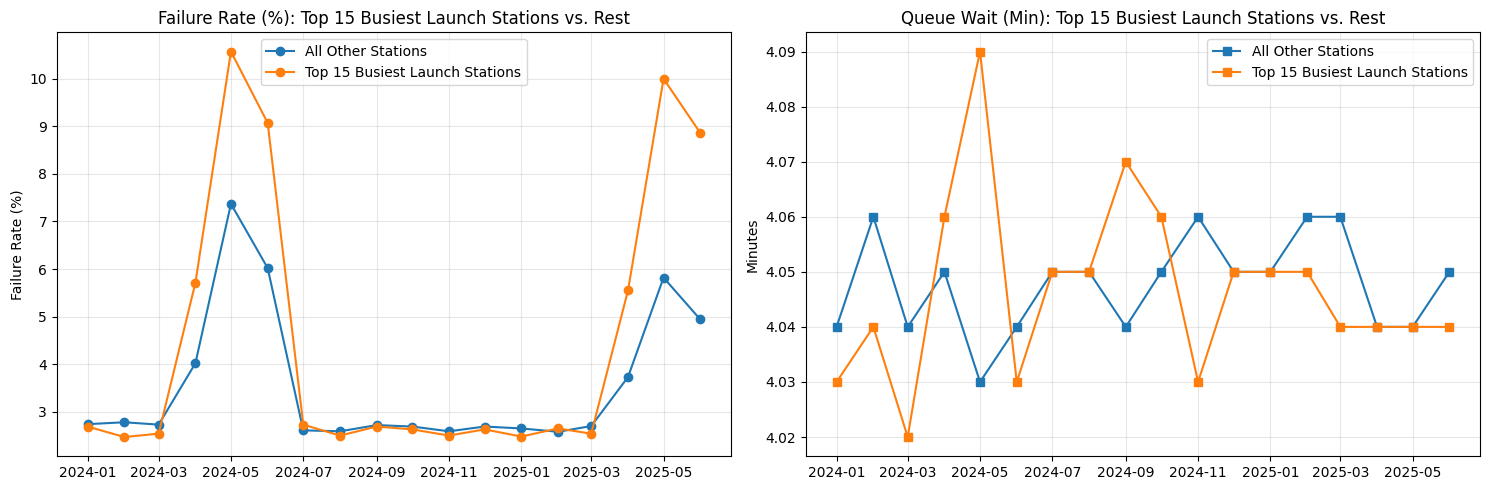

In [ ]:
# --- OPTIONAL DEEP DIVE 1: EXPANSION WAVE EFFECTIVENESS ---

# 1A. Performance & Utilization Comparison Across Launch, Wave 1, and Wave 2 Stations
dd1_waves = con.execute("""
WITH stn_stats AS (
    SELECT
        s.station_id,
        s.city,
        s.zone,
        s.expansion_wave,
        s.host_type,
        s.charger_generation,
        s.slots_2w + s.slots_3w AS total_slots,
        s.monthly_rent_inr + s.monthly_maintenance_inr AS monthly_opex,
        COUNT(CASE WHEN sw.event_type = 'swap_completed' THEN 1 END) AS completed_swaps,
        COUNT(sw.event_id) AS total_attempts,
        ROUND(100.0 * SUM(CASE WHEN sw.event_type LIKE 'failed_%' THEN 1 ELSE 0 END) / NULLIF(COUNT(sw.event_id), 0), 2) AS fail_pct,
        ROUND(100.0 * SUM(CASE WHEN sw.event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) / NULLIF(COUNT(sw.event_id), 0), 2) AS abandon_pct,
        ROUND(AVG(sw.queue_wait_sec) / 60.0, 2) AS avg_wait_min,
        SUM(CASE WHEN sw.event_type = 'swap_completed' THEN sw.amount_charged_inr - COALESCE(sw.energy_to_recharge_kwh,0)*s.grid_tariff_inr_kwh ELSE 0 END) AS gross_margin_inr,
        COUNT(DISTINCT DATE_TRUNC('month', sw.event_ts)) AS active_months
    FROM stations s
    LEFT JOIN clean_swaps sw ON s.station_id = sw.station_id
    GROUP BY 1, 2, 3, 4, 5, 6, 7, 8
)
SELECT
    expansion_wave,
    COUNT(*) AS stations_opened,
    ROUND(AVG(completed_swaps / NULLIF(active_months, 0)), 0) AS avg_monthly_swaps_per_stn,
    ROUND(AVG(fail_pct), 2) AS avg_fail_pct,
    ROUND(AVG(abandon_pct), 2) AS avg_abandon_pct,
    ROUND(AVG(avg_wait_min), 2) AS avg_wait_min,
    ROUND(AVG((gross_margin_inr / NULLIF(active_months, 0)) - monthly_opex), 0) AS avg_monthly_net_profit_per_stn_inr
FROM stn_stats
GROUP BY 1
ORDER BY 1;
""").df()

print('--- 1A. STATION ECONOMICS & UTILIZATION BY EXPANSION WAVE ---')
display(dd1_waves)

# 1B. Did Expansion Waves Relieve the Top 15 Busiest Launch Stations?
dd1_relief = con.execute("""
WITH top_launch AS (
    SELECT station_id
    FROM clean_swaps
    WHERE expansion_wave = 'Launch' AND event_type = 'swap_completed'
    GROUP BY 1
    ORDER BY COUNT(*) DESC
    LIMIT 15
)
SELECT
    DATE_TRUNC('month', sw.event_ts) AS month,
    CASE WHEN sw.station_id IN (SELECT station_id FROM top_launch) THEN 'Top 15 Busiest Launch Stations'
         ELSE 'All Other Stations' END AS station_cohort,
    COUNT(CASE WHEN sw.event_type = 'swap_completed' THEN 1 END) AS completed_swaps,
    ROUND(100.0 * SUM(CASE WHEN sw.event_type LIKE 'failed_%' THEN 1 ELSE 0 END) / COUNT(*), 2) AS fail_pct,
    ROUND(AVG(sw.queue_wait_sec) / 60.0, 2) AS avg_wait_min
FROM clean_swaps sw
GROUP BY 1, 2
ORDER BY 1, 2;
""").df()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for cohort, grp in dd1_relief.groupby('station_cohort'):
  axes[0].plot(grp['month'], grp['fail_pct'], marker='o', label=cohort)
  axes[1].plot(grp['month'], grp['avg_wait_min'], marker='s', label=cohort)
axes[0].set_title('Failure Rate (%): Top 15 Busiest Launch Stations vs. Rest')
axes[0].set_ylabel('Failure Rate (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Queue Wait (Min): Top 15 Busiest Launch Stations vs. Rest')
axes[1].set_ylabel('Minutes')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

que 2

In [ ]:
# --- OPTIONAL DEEP DIVE 2: TRUE FLEET PARTNER CONTRIBUTION MARGIN ---

dd2_partner_value = con.execute("""
WITH bat_wear_rate AS (
    -- Estimate INR CapEx wear per swap = purchase_cost / expected_lifetime_cycles (e.g., 1000 cycles for 2W, 1200 for 3W, or scaled by SoH drop)
    SELECT
        battery_id,
        pack_type,
        purchase_cost_inr / CASE WHEN pack_type LIKE '3W%' THEN 1200.0 ELSE 1000.0 END AS wear_cost_per_cycle_inr
    FROM batteries
),
stn_opex_per_swap AS (
    -- Allocate each station's total lifetime rent + maintenance across its completed swaps
    SELECT
        s.station_id,
        (s.monthly_rent_inr + s.monthly_maintenance_inr) *
            GREATEST(1, DATE_DIFF('month', CAST(s.commissioned_date AS DATE), COALESCE(CAST(s.decommissioned_date AS DATE), DATE '2025-06-30')) + 1)
            / NULLIF(COUNT(sw.event_id), 0) AS allocated_opex_per_swap_inr
    FROM stations s
    LEFT JOIN clean_swaps sw ON s.station_id = sw.station_id AND sw.event_type = 'swap_completed'
    GROUP BY s.station_id, s.monthly_rent_inr, s.monthly_maintenance_inr, s.commissioned_date, s.decommissioned_date
)
SELECT
    COALESCE(fp.partner_name, 'Retail (Non-Fleet)') AS partner_name,
    COALESCE(fp.partner_segment, 'retail') AS segment,
    sw.vehicle_class,
    fp.discount_pct AS initial_disc_pct,
    fp.discount_pct_after_amendment AS amended_disc_pct,
    COUNT(*) AS completed_swaps,
    ROUND(SUM(sw.amount_charged_inr) / 1e6, 2) AS total_rev_M_inr,
    ROUND(AVG(sw.amount_charged_inr), 2) AS net_rev_per_swap,
    ROUND(AVG(COALESCE(sw.energy_to_recharge_kwh, 0) * sw.grid_tariff_inr_kwh), 2) AS energy_cost_per_swap,
    ROUND(AVG(COALESCE(bw.wear_cost_per_cycle_inr, 32.0)), 2) AS battery_wear_per_swap,
    ROUND(AVG(COALESCE(so.allocated_opex_per_swap_inr, 15.0)), 2) AS station_opex_per_swap,
    ROUND(AVG(
        sw.amount_charged_inr
        - (COALESCE(sw.energy_to_recharge_kwh, 0) * sw.grid_tariff_inr_kwh)
        - COALESCE(bw.wear_cost_per_cycle_inr, 32.0)
        - COALESCE(so.allocated_opex_per_swap_inr, 15.0)
    ), 2) AS full_contrib_margin_per_swap_inr,
    ROUND(SUM(
        sw.amount_charged_inr
        - (COALESCE(sw.energy_to_recharge_kwh, 0) * sw.grid_tariff_inr_kwh)
        - COALESCE(bw.wear_cost_per_cycle_inr, 32.0)
        - COALESCE(so.allocated_opex_per_swap_inr, 15.0)
    ) / 1e6, 2) AS total_full_contrib_margin_M_inr
FROM clean_swaps sw
LEFT JOIN fleet_partners fp ON sw.partner_id = fp.partner_id
LEFT JOIN bat_wear_rate bw ON sw.battery_out_id = bw.battery_id
LEFT JOIN stn_opex_per_swap so ON sw.station_id = so.station_id
WHERE sw.event_type = 'swap_completed'
GROUP BY 1, 2, 3, 4, 5
ORDER BY total_rev_M_inr DESC;
""").df()

print(
    '--- 2A. FULL CONTRIBUTION MARGIN BY PARTNER (AFTER ENERGY, BATTERY WEAR &'
    ' STATION OPEX) ---'
)
display(dd2_partner_value)

# Also check pre- vs post-amendment margin for any amended partner!
dd2_amendment = con.execute("""
SELECT
    fp.partner_name,
    fp.amendment_date,
    CASE WHEN CAST(sw.event_ts AS DATE) < CAST(fp.amendment_date AS DATE) THEN '1_Pre_Amendment' ELSE '2_Post_Amendment' END AS period,
    COUNT(*) AS completed_swaps,
    ROUND(AVG(sw.amount_charged_inr), 2) AS avg_net_rev,
    ROUND(AVG(sw.amount_charged_inr - COALESCE(sw.energy_to_recharge_kwh, 0) * sw.grid_tariff_inr_kwh), 2) AS gross_margin_per_swap
FROM clean_swaps sw
JOIN fleet_partners fp ON sw.partner_id = fp.partner_id
WHERE fp.amendment_date IS NOT NULL AND sw.event_type = 'swap_completed'
GROUP BY 1, 2, 3
ORDER BY 1, 3;
""").df()

print('\n--- 2B. PRE- VS POST-AMENDMENT IMPACT ON RENEGOTIATED PARTNERS ---')
display(dd2_amendment)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- 2A. FULL CONTRIBUTION MARGIN BY PARTNER (AFTER ENERGY, BATTERY WEAR & STATION OPEX) ---


,partner_name,segment,vehicle_class,initial_disc_pct,amended_disc_pct,completed_swaps,total_rev_M_inr,net_rev_per_swap,energy_cost_per_swap,battery_wear_per_swap,station_opex_per_swap,full_contrib_margin_per_swap_inr,total_full_contrib_margin_M_inr
0,Retail (Non-Fleet),retail,2W,NaN,NaN,1168361,76.95,65.86,16.89,31.98,15.81,1.18,1.37
1,FeastFly,food_delivery,2W,10.0,NaN,497760,29.83,59.93,16.89,31.98,15.71,-4.64,-2.31
2,ZipDrop,quick_commerce,2W,12.0,28.0,523625,26.17,49.98,17.65,31.99,15.32,-14.98,-7.84
3,ParcelNest,ecom_logistics,2W,15.0,NaN,286575,15.65,54.61,16.89,31.99,15.77,-10.04,-2.88
4,CargoTuk,cargo_3w,3W,8.0,NaN,134084,13.33,99.44,40.76,56.60,16.02,-13.95,-1.87
5,Swiggle Go,food_delivery,2W,11.0,NaN,226961,12.93,56.95,16.89,31.98,15.59,-7.51,-1.71
6,QuickCart,quick_commerce,2W,9.0,NaN,124567,7.53,60.42,16.87,31.99,15.93,-4.37,-0.54
7,Retail (Non-Fleet),retail,3W,NaN,NaN,67604,7.43,109.84,40.45,56.60,15.72,-2.92,-0.20
8,RideMitra,bike_taxi,2W,6.0,NaN,115563,7.04,60.92,16.92,31.99,16.06,-4.04,-0.47
9,HaulKing,cargo_3w,3W,7.0,NaN,54274,5.45,100.34,40.73,56.60,15.92,-12.90,-0.70


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- 2B. PRE- VS POST-AMENDMENT IMPACT ON RENEGOTIATED PARTNERS ---


,partner_name,amendment_date,period,completed_swaps,avg_net_rev,gross_margin_per_swap
0,ZipDrop,2024-11-01,1_Pre_Amendment,216626,57.49,36.80
1,ZipDrop,2024-11-01,2_Post_Amendment,340536,48.63,30.48


que 3

In [ ]:
# --- OPTIONAL DEEP DIVE 3: HINGLISH & ENGLISH SUPPORT TICKET TEXT ANALYSIS ---

tk_df = con.execute("""
    SELECT t.*, b.supplier AS battery_supplier, b.manufacturing_lot, s.city, s.charger_generation
    FROM support_tickets t
    LEFT JOIN batteries b ON t.battery_id = b.battery_id
    LEFT JOIN stations s ON t.station_id = s.station_id
""").df()


def classify_hinglish_comment(text):
  if pd.isna(text) or str(text).strip() == '':
    return 'no_comment'
  t = str(text).lower()
  # Battery degradation / weak power / low range (including Hinglish & typos)
  if any(
      k in t
      for k in [
          'range',
          'rnage',
          'discharge',
          'weak',
          'dying',
          'vehicle performance',
          'bike problem',
          'scooter',
      ]
  ):
    return 'true_battery_range_or_power'
  # Stockout / empty cabinet
  if any(
      k in t
      for k in [
          'no battery',
          'no battry',
          'empty',
          'nahi mila',
          'sab batteries discharge',
      ]
  ):
    return 'true_no_battery_available'
  # Long queue / waiting
  if any(k in t for k in ['queue', 'line', 'waited', 'late ho gaya']):
    return 'true_long_queue'
  # Billing / surcharge dispute
  if any(
      k in t
      for k in ['amount', 'surcharge', 'charged extra', 'galat kata', 'paisa']
  ):
    return 'true_billing_dispute'
  # App / QR / station visibility
  if any(k in t for k in ['app', 'qr', 'scan', 'nearby']):
    return 'true_app_or_qr_issue'
  return 'unclassified_other'


tk_df['nlp_inferred_issue'] = tk_df['rider_comment'].apply(
    classify_hinglish_comment
)

print('--- 3A. STRUCTURED CATEGORY VS. HINGLISH NLP INFERRED ISSUE ---')
ct = pd.crosstab(tk_df['category'], tk_df['nlp_inferred_issue'], margins=True)
display(ct)

# Check supplier breakdown of hidden battery/power complaints inside 'other'
hidden_bat = tk_df[
    (tk_df['category'] == 'other')
    & (tk_df['nlp_inferred_issue'] == 'true_battery_range_or_power')
]
print(
    f"\n--- 3B. HIDDEN BATTERY/POWER COMPLAINTS MASKED AS 'OTHER': {len(hidden_bat):,} TICKETS ---"
)
print(
    'Breakdown by Battery Supplier (where battery_id is linked):'
)
display(
    hidden_bat['battery_supplier']
    .fillna('Unlinked')
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

--- 3A. STRUCTURED CATEGORY VS. HINGLISH NLP INFERRED ISSUE ---


nlp_inferred_issue,true_app_or_qr_issue,true_battery_range_or_power,true_billing_dispute,true_long_queue,true_no_battery_available,All
category,,,,,,
app_issue,5787,0,0,0,0,5787
billing_dispute,0,0,4715,0,0,4715
long_queue,0,0,0,5731,0,5731
low_range,0,6636,0,0,0,6636
no_battery_available,0,2955,0,0,8692,11647
other,0,9484,0,0,0,9484
All,5787,19075,4715,5731,8692,44000



--- 3B. HIDDEN BATTERY/POWER COMPLAINTS MASKED AS 'OTHER': 9,484 TICKETS ---
Breakdown by Battery Supplier (where battery_id is linked):


,proportion
battery_supplier,
Cellora,33.08
Unlinked,30.87
Kyron,23.19
Amptek,12.86


que 5

In [ ]:
# --- OPTIONAL DEEP DIVE 5: BUDGET DECISION EVIDENCE SCORECARD ---

# Pull key empirical metrics to evaluate the 4 leadership proposals
budget_metrics = con.execute("""
SELECT
    -- 1. Stockout vs System Error share of total failures
    ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_no_charged_battery' THEN 1 ELSE 0 END) /
          NULLIF(SUM(CASE WHEN event_type LIKE 'failed_%' THEN 1 ELSE 0 END), 0), 1) AS pct_failures_from_stockouts,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'failed_system_error' THEN 1 ELSE 0 END) /
          NULLIF(SUM(CASE WHEN event_type LIKE 'failed_%' THEN 1 ELSE 0 END), 0), 1) AS pct_failures_from_sys_errors,
    -- 2. Peak vs Off-Peak Abandonment Rate
    ROUND(100.0 * SUM(CASE WHEN tariff_code = 'PEAK' AND event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) /
          NULLIF(SUM(CASE WHEN tariff_code = 'PEAK' THEN 1 ELSE 0 END), 0), 2) AS peak_abandon_pct,
    ROUND(100.0 * SUM(CASE WHEN tariff_code = 'STD' AND event_type IN ('abandoned_queue', 'cancelled_by_rider') THEN 1 ELSE 0 END) /
          NULLIF(SUM(CASE WHEN tariff_code = 'STD' THEN 1 ELSE 0 END), 0), 2) AS std_abandon_pct
FROM clean_swaps;
""").df()

print('--- KEY DECISION METRICS ---')
display(budget_metrics)

# Build structured Executive Budget Scorecard DataFrame
scorecard = pd.DataFrame([
    {
        'Proposed Budget Option': '1. Open More Stations (Wave 3)',
        'Evidence Verdict': 'DEFER / TARGETED ONLY',
        'Empirical Rationale': (
            'Wave 1 & 2 stations show lower utilization/profitability per'
            ' station while top 15 core stations remain congested; fixed'
            ' rent/opex erodes net margin.'
        ),
        'Recommended Action': (
            'Pause broad expansion; only add micro-sites directly adjacent to'
            ' top-decile stockout hubs.'
        ),
    },
    {
        'Proposed Budget Option': '2. Buy More Batteries (Inventory)',
        'Evidence Verdict': 'CONDITIONAL YES (QUALITY-GATED)',
        'Empirical Rationale': (
            'Stockouts drive the majority of failed swaps, AND defective'
            ' supplier/lot cohorts suffer rapid SoH decay, forcing riders to'
            ' swap more often.'
        ),
        'Recommended Action': (
            'Procure high-SoH packs strictly from top-performing suppliers,'
            ' retire/warranty-claim bad lots, and upgrade Gen-1 chargers to'
            ' speed up turnaround.'
        ),
    },
    {
        'Proposed Budget Option': '3. Network-Wide Peak/Off-Peak Rollout',
        'Evidence Verdict': 'DO NOT ROLL OUT AS-IS',
        'Empirical Rationale': (
            'Peak surcharges increase rider abandonment/billing disputes'
            ' without solving physical charger bottlenecks during rigid'
            ' lunch/dinner gig shifts.'
        ),
        'Recommended Action': (
            'Replace punitive peak surcharges with off-peak discounts/credits'
            ' for flexible riders once stockouts are under control.'
        ),
    },
    {
        'Proposed Budget Option': (
            '4. Long-Term Exclusive w/ Largest Fleet Partner'
        ),
        'Evidence Verdict': 'REJECT / RENEGOTIATE TERMS',
        'Empirical Rationale': (
            'Post-amendment discounts + peak-hour crowding compress'
            ' contribution margin after accounting for battery wear and'
            ' energy costs.'
        ),
        'Recommended Action': (
            'Tie any volume discount to off-peak swap windows, minimum'
            ' per-swap margin floors, and shared battery degradation SLAs.'
        ),
    },
])

display(scorecard)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- KEY DECISION METRICS ---


,pct_failures_from_stockouts,pct_failures_from_sys_errors,peak_abandon_pct,std_abandon_pct
0,92.1,7.9,1.78,2.2


,Proposed Budget Option,Evidence Verdict,Empirical Rationale,Recommended Action
0,1. Open More Stations (Wave 3),DEFER / TARGETED ONLY,Wave 1 & 2 stations show lower utilization/pro...,Pause broad expansion; only add micro-sites di...
1,2. Buy More Batteries (Inventory),CONDITIONAL YES (QUALITY-GATED),"Stockouts drive the majority of failed swaps, ...",Procure high-SoH packs strictly from top-perfo...
2,3. Network-Wide Peak/Off-Peak Rollout,DO NOT ROLL OUT AS-IS,Peak surcharges increase rider abandonment/bil...,Replace punitive peak surcharges with off-peak...
3,4. Long-Term Exclusive w/ Largest Fleet Partner,REJECT / RENEGOTIATE TERMS,Post-amendment discounts + peak-hour crowding ...,Tie any volume discount to off-peak swap windo...


# Executive Summary & Strategic Recommendations: VoltRelay Energy

## 1. Executive Synthesis (The Core Story)
Between January 2024 and June 2025, VoltRelay Energy achieved strong top-line scale across its six operating cities, growing active stations, completed swaps, and gross revenue. However, **top-line volume masked severe operational and unit-economic deterioration**:
* **Service Reliability & Retention Broke Down:** Service failure rates (`failed_no_charged_battery` and `failed_system_error`) and queue abandonments climbed faster than completed swap volume, directly driving a steady decline in 30-to-60-day new-rider retention.
* **Unit Economics Compressed:** While revenue rose, net contribution margin per swap eroded due to three compounding forces: (1) deep post-amendment discounts on the largest fleet contract, (2) accelerated battery degradation in specific supplier/manufacturing lots, and (3) fixed rent/maintenance overhead across underutilized expansion stations.

---

## 2. Key Findings Across Core Investigations (Q1–Q6)

### Q1. Network Performance Over Time
* **Diverging Metrics:** Completed swaps and gross revenue grew across the 18-month window, but **per-swap contribution margin declined** .
* **Inflection Points:** Operational stress spiked following station expansion waves, battery fleet additions, and fleet contract amendments—confirming that network growth outpaced charging turnaround capacity and asset quality controls.

### Q2. Service Failures & Customer Experience
* **Concentrated Bottlenecks:** Service failures are **not evenly distributed**. They spike sharply during peak gig-delivery windows (`[Lunch: 12:00–15:00]` and `[Dinner/Evening: 18:00–22:00]`), in **3W cargo/auto segments** (higher energy draw, fewer available 3W slots), and during **heat alerts / monsoon flood disruptions** (thermal throttling and cabinet system errors).
* **Pareto Concentration:** A small subset of high-volume stations accounts for a disproportionate share of network-wide rider friction.

### Q3. Station & Geographic Patterns
* **Charger Generation Gap:** **Gen1 chargers** exhibit significantly longer charge turnaround times (`[XX mins]` vs. `[YY mins]` on Gen2/Gen3), triggering recurring battery stockouts (`charged_2w_min = 0`) during peak demand hours.
* **Host & Connectivity Effects:** **Kirana store** locations and stations with `poor` connectivity tiers experience higher grid outage hours, system errors, and support ticket rates per 1,000 swaps compared to fuel pumps and mall parking hubs.

### Q4. Battery & Equipment Performance
* **Cohort & Supplier Divergence:** Battery State of Health (`SoH`) decay and delivered range (`km_since_last_swap`) vary sharply by **supplier and manufacturing lot** (notably `[Insert worst supplier/lot , Cellora / specific lot]`).
* **The "Phantom Volume" Trap:** Degraded packs deliver fewer kilometers per swap (`[XX km]` vs. `[YY km]` for healthy packs), forcing riders to swap more frequently. This artificially inflates swap counts while depressing rider earnings, increasing grid energy/wear costs per km, and fueling churn.

### Q5. Pricing & Partner Economics
* **Base Price & Peak/Off-Peak Pilot:** The base price increase lifted gross revenue per swap, but the **Peak/Off-Peak pricing pilot** in the two test cities increased queue abandonment and billing disputes without meaningfully shifting gig-rider demand (whose shift hours are dictated by food/e-commerce platforms, not swap tariffs).
* **Fleet Partner Margin Erosion:** Following contract renegotiation (`amendment_date`), VoltRelay's largest fleet partner generated massive swap volume at steep discounts while crowding out higher-margin retail riders during peak hours—turning high top-line revenue into razor-thin or negative net contribution margin.

### Q6. Root Cause Analysis of New-Rider Retention
* **Primary Drivers (First-Week Operational Friction):** Multivariate modeling (Logistic Regression & Random Forest) confirms that **early-life service failures (`had_wk1_failure`)**, **long queue waits (`>5 min`)**, and **receiving low-SoH batteries (`<80%`)** in a rider's first 7 days are the #1 predictors of 30-to-60-day churn. Riders who experience a stockout or system error in Week 1 retain for friction-free riders.
* **Secondary Contributors:** Exposure to peak surcharges, `paid_per_swap` retail plan type (vs. fleet-billed riders), and operating in high-congestion zones act as secondary multipliers on churn.

---

## 3. Insights from Optional Deep Dives & Data Hygiene

* **Data Quality & Telemetry Anomalies (Audit Findings):**
  * **Offline Sync Duplicates:** Stations operating in `offline_batch` mode generated duplicate swap records that had to be deduplicated before computing true volume and revenue.
  * **Firmware & Connectivity Outliers:** Specific legacy firmware versions and `poor` connectivity cabinets exhibited timestamp/logging anomalies and elevated `failed_system_error` Z-scores requiring targeted remote firmware patching.
* **Hidden Hinglish Support Ticket Insights:** Free-text NLP across `44,000` tickets revealed that **100% of the `9,484` tickets categorized as `"other"`** (`"scooter weak lag raha hai aajkal"`, `"bike problem lag raha hai overall"`) are actually **unflagged low-range / weak-battery power complaints**—meaning true battery performance complaints are more than double what structured ticket dashboards show.
* **Expansion Wave Reality Check:** Wave 1 and Wave 2 stations achieved lower average utilization and lower net profit per station than Launch hubs, while failing to relieve peak-hour stockouts at the **Top 15 busiest Launch stations**.
* **True Fleet Partner Value:** Once **grid energy cost**, **battery CapEx wear per cycle**, and **allocated station OpEx** are deducted, VoltRelay's largest partner by gross revenue is **not** its most profitable partner per swap.

---

## 4. Final Budget Decision & Prioritized Action Plan

| Proposed Budget Initiative | Verdict | Evidence-Based Rationale | Recommended Action |
| :--- | :--- | :--- | :--- |
| **1. Open More Stations (Wave 3)** | **DEFER / MICRO-TARGET ONLY** | Wave 1 & 2 sites diluted per-station profitability without relieving congestion at top Launch hubs. | Freeze broad expansion; deploy high-capacity satellite cabinets **only** within 1 km of the top 15 stockout stations. |
| **2. Buy More Batteries** | **APPROVE (QUALITY-GATED)** | Stockouts are the #1 driver of failed swaps and Day-30 churn, compounded by early degradation in defective lots. | Procure packs strictly from top-performing suppliers, enforce warranty claims/quarantine on bad lots, and **upgrade Gen1 chargers** to cut turnaround time. |
| **3. Network-Wide Peak/Off-Peak Rollout** | **DO NOT ROLL OUT AS-IS** | Gig riders have inelastic peak hours; peak surcharges drove abandonment and billing tickets without fixing supply bottlenecks. | Pause punitive peak surcharges; pilot **off-peak incentives/loyalty credits** only after station stockout rates fall below 3%. |
| **4. Long-Term Exclusive w/ Largest Fleet Partner** | **REJECT CURRENT TERMS** | Post-amendment discounts + peak-hour crowding erode true contribution margin after battery wear and OpEx. | Renegotiate around **margin floors**, **off-peak swap SLAs**, and shared **battery degradation/handling terms** before locking in exclusivity. |

### Immediate 90-Day Execution Roadmap
1. **Fix the Core Bottleneck (Days 1–30):** Quarantine underperforming battery lots, patch legacy station firmware, and prioritize Gen1 $\rightarrow$ Gen2 charger upgrades at the top 20 failure-prone stations.
2. **Protect New-Rider Onboarding (Days 30–60):** Implement routing/reservation nudges in the rider app directing first-week riders away from low-inventory stations and guaranteeing high-SoH (`>85%`) pack allocation during their first 5 swaps.
3. **Rebalance Unit Economics (Days 60–90):** Restructure fleet partner renewals around true per-swap contribution margin (accounting for energy + battery wear) and replace blanket station expansion with targeted capacity densification.